# Checkpoint Three: Exploratory Analysis
**CS 418 · Socioeconomic Health Disparities · Group: Anirudh Gupta, Claudia Jimenez, Andrew Mcclendon, Auon Muhammad Naqvi, Jesus Rodriguez**

*(Rubric: 1 profiles · 2 anomalies · 3 distributions · 4 relationships (≥3, incl. the join) · 5 "so what" · 6 "what next")*

In [1]:
# ---- SHARED SETUP: don't edit. Run this first. ---- #
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pl.Config.set_tbl_cols(-1)

pop    = pl.read_csv("data/Chicago_Community_Population_Data.csv", infer_schema_length=10000)               # primary
air    = pl.read_csv("https://data.cityofchicago.org/api/v3/views/rtmx-vkjr/export.csv?accessType=DOWNLOAD&app_token=bHWsGtRFRP9x8Hl8lYivqM1hQ", infer_schema_length=10000) # primary
income = pl.read_csv("data/Chicago_Median_Income_By_Community_Area.csv", infer_schema_length=10000)         # secondary
emis   = pl.read_csv("data/CommunityAreas_LocalEmission2019.csv", infer_schema_length=10000)                # secondary

---
# Population dataset
**Owner: Andrew** · Primary dataset: `data/Chicago_Community_Population_Data.csv`

## Step 1 · Profile

In [84]:
print(pop.shape)
print(pop.schema)
pop.glimpse()

(77, 30)
Schema({'ACS Year': Int64, 'Community Area': String, 'Under $25,000': String, '$25,000 to $49,999': String, '$50,000 to $74,999': String, '$75,000 to $125,000': String, '$125,000 +': String, 'Male 0 to 17': String, 'Male 18 to 24': String, 'Male 25 to 34': String, 'Male 35 to 49': String, 'Male 50 to 64': String, 'Male 65+': String, 'Female 0 to 17': String, 'Female 18 to 24': String, 'Female 25 to 34': String, 'Female 35 to 49': String, 'Female 50 to 64': String, 'Female 65 +': String, 'Total Population': String, 'White': String, 'Black or African American': String, 'American Indian or Alaska Native': String, 'Asian': String, 'Native Hawaiian or Pacific Islander': Int64, 'Other Race': String, 'Multiracial': String, 'White Not Hispanic or Latino': String, 'Hispanic or Latino': String, 'Record ID': String})
Rows: 77
Columns: 30
$ ACS Year                            <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ Community Area                      <str> 'ALBA

All listed race had at least one area where their population count was in the single or double digits.

In [85]:
pop.null_count()

ACS Year,Community Area,"Under $25,000","$25,000 to $49,999","$50,000 to $74,999","$75,000 to $125,000","$125,000 +",Male 0 to 17,Male 18 to 24,Male 25 to 34,Male 35 to 49,Male 50 to 64,Male 65+,Female 0 to 17,Female 18 to 24,Female 25 to 34,Female 35 to 49,Female 50 to 64,Female 65 +,Total Population,White,Black or African American,American Indian or Alaska Native,Asian,Native Hawaiian or Pacific Islander,Other Race,Multiracial,White Not Hispanic or Latino,Hispanic or Latino,Record ID
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Good data set, not missing any data

In [86]:
pop.describe()

statistic,ACS Year,Community Area,"Under $25,000","$25,000 to $49,999","$50,000 to $74,999","$75,000 to $125,000","$125,000 +",Male 0 to 17,Male 18 to 24,Male 25 to 34,Male 35 to 49,Male 50 to 64,Male 65+,Female 0 to 17,Female 18 to 24,Female 25 to 34,Female 35 to 49,Female 50 to 64,Female 65 +,Total Population,White,Black or African American,American Indian or Alaska Native,Asian,Native Hawaiian or Pacific Islander,Other Race,Multiracial,White Not Hispanic or Latino,Hispanic or Latino,Record ID
str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str
"""count""",77.0,"""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""",77.0,"""77""","""77""","""77""","""77""","""77"""
"""null_count""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""",0.0,"""0""","""0""","""0""","""0""","""0"""
"""mean""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,17.909091,null,null,null,null,null
"""std""",0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,34.429249,null,null,null,null,null
"""min""",2023.0,"""ALBANY PARK""","""1,007""","""1,022""","""1,002""","""1,019""","""1,030""","""1,099""","""1,042""","""1,052""","""1,005""","""1,057""","""1,010""","""1,022""","""1,018""","""1,027""","""1,056""","""1,001""","""1,021""","""100,278""","""1,123""","""1,079""","""0""","""0""",0.0,"""0""","""1,015""","""1,066""","""1,114""","""2023_ALBANY PARK"""
"""25%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,null
"""50%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,null
"""75%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,21.0,null,null,null,null,null
"""max""",2023.0,"""WOODLAWN""","""965""","""997""","""974""","""979""","""988""","""930""","""940""","""933""","""9,920""","""8,110""","""853""","""9,697""","""978""","""978""","""9,695""","""999""","""909""","""91,635""","""908""","""991""","""993""","""991""",171.0,"""993""","""936""","""995""","""981""","""2023_WOODLAWN"""


Not as informative because the min and max dont tell me which area its from

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
| N/A | N/A  | N/A   | N/A  |

## Step 3 · Distributions
One plot per feature that matters to the research questions.

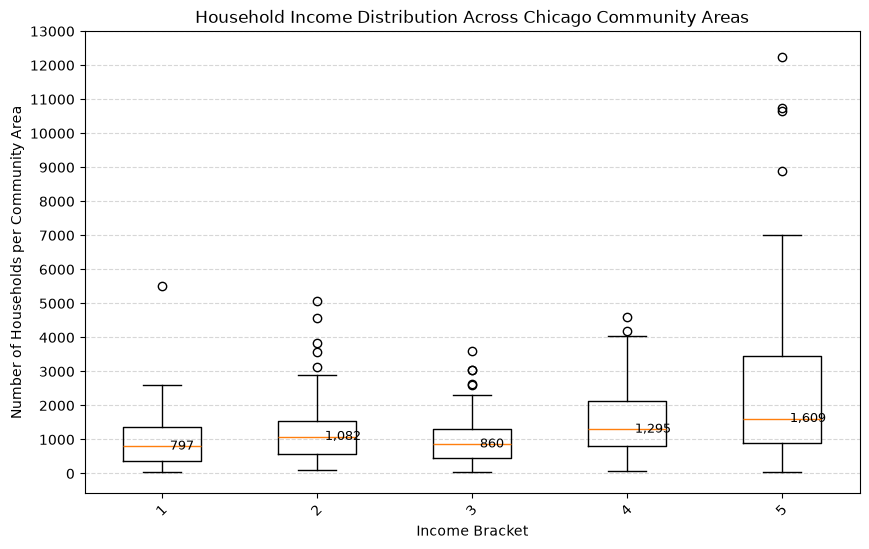

In [87]:
import polars as pl
import matplotlib.pyplot as plt

income_cols = [
    'Under $25,000',
    '$25,000 to $49,999',
    '$50,000 to $74,999',
    '$75,000 to $125,000',
    '$125,000 +'
]

income_labels = [
    'Under $25,000',
    '$25,000 - $49,999',
    '$50,000 - $74,999',
    '$75,000 - $125,000',
    '$125,000+'
]

for col in income_cols:
    if pop.schema[col] == pl.String:
        pop = pop.with_columns(
            pl.col(col)
            .str.replace_all(",", "")
            .cast(pl.Int64)
        )

data = [
    pop[col].drop_nulls().to_list()
    for col in income_cols
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    data,
    label=income_labels
)

medians = [
    pop[col].median()
    for col in income_cols
]

for i, median in enumerate(medians, start=1):
    plt.text(
        i + 0.05,
        median,
        f'{median:,.0f}',
        verticalalignment='center',
        fontsize=9
    )

plt.title("Household Income Distribution Across Chicago Community Areas")
plt.xlabel("Income Bracket")
plt.ylabel("Number of Households per Community Area")

plt.yticks(range(0, 13001, 1000))

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

plt.xticks(rotation=45)


plt.show()

**Distribution 1: [feature name]**
- **Center:** The median househould dont get above 2000 but stil vary but hovers between about 800 and 1600
- **Spread:** 125,000 has the gratest variability and lonest whiskers and the under 250000 have smaller spreads. It seems wealthier income communites tend to group 
- **Skew / shape:** all brackets are right skewed
- **Outliers:** every category has outliers on the increasing side


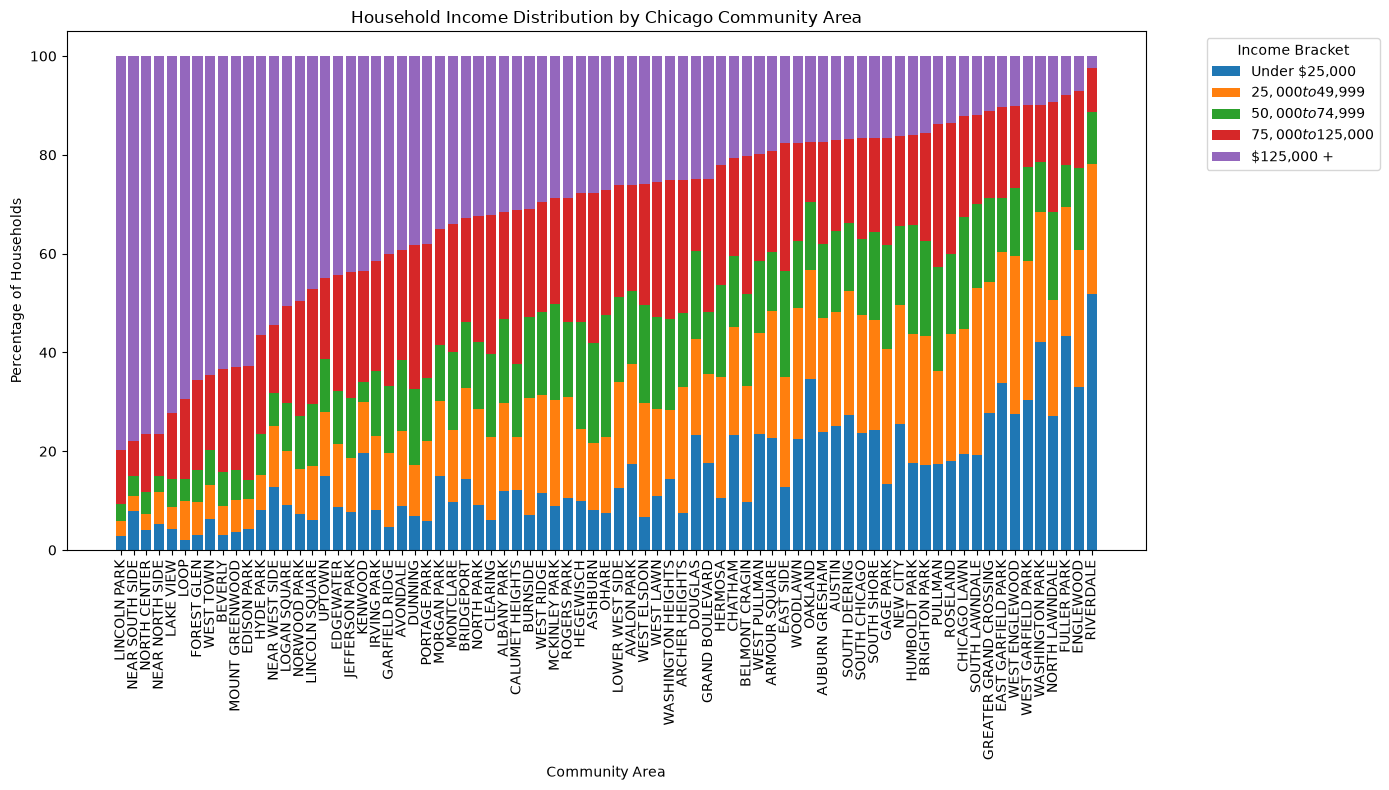

In [88]:


income_cols = [
    'Under $25,000',
    '$25,000 to $49,999',
    '$50,000 to $74,999',
    '$75,000 to $125,000',
    '$125,000 +'
]

income_labels = [
    'Under $25,000',
    '$25,000 - $49,999',
    '$50,000 - $74,999',
    '$75,000 - $125,000',
    '$125,000+'
]



for col in income_cols:
    if pop.schema[col] == pl.String:
        pop = pop.with_columns(
            pl.col(col)
            .str.replace_all(",", "")
            .cast(pl.Int64)
        )


neighborhood_col = "Community Area"


pop = pop.with_columns(
    pl.sum_horizontal(income_cols).alias("Total Households")
)


for col in income_cols:
    pop = pop.with_columns(
        (pl.col(col) / pl.col("Total Households") * 100)
        .alias(col + " %")
    )


pop = pop.sort("$125,000 + %", descending=True)

neighborhoods = pop[neighborhood_col].to_list()

plt.figure(figsize=(14, 8))

bottom = [0] * len(neighborhoods)

for col in income_cols:
    values = pop[col + " %"].to_list()

    plt.bar(
        neighborhoods,
        values,
        bottom=bottom,
        label=col
    )

    bottom = [
        bottom[i] + values[i]
        for i in range(len(values))
    ]

plt.title("Household Income Distribution by Chicago Community Area")
plt.xlabel("Community Area")
plt.ylabel("Percentage of Households")

plt.xticks(rotation=90)

plt.legend(title="Income Bracket", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

---
# Open Air Chicago dataset
**Owner: Claudia** · Primary dataset: `Open_Air_Chicago_Day_Aggregations`

## Step 1 · Profile

In [2]:
air.shape

(117320, 46)

In [3]:
air.schema

Schema([('datasourceid', String),
        ('outputfrequency', String),
        ('startofperiod', String),
        ('sensor_name', String),
        ('atmPressure24HourMean.raw', String),
        ('atmPressure24HourMean.value', String),
        ('bcAllSources24HourMean.raw', String),
        ('bcAllSources24HourMean.value', String),
        ('bcBiomass24HourMean.raw', String),
        ('bcBiomass24HourMean.value', String),
        ('bcFossilFuel24HourMean.raw', String),
        ('bcFossilFuel24HourMean.value', String),
        ('bcSpectralB24HourMean.raw', String),
        ('bcSpectralB24HourMean.value', String),
        ('bcSpectralG24HourMean.raw', String),
        ('bcSpectralG24HourMean.value', String),
        ('bcSpectralIR24HourMean.raw', String),
        ('bcSpectralIR24HourMean.value', String),
        ('bcSpectralR24HourMean.raw', String),
        ('bcSpectralR24HourMean.value', String),
        ('bcSpectralUV24HourMean.raw', String),
        ('bcSpectralUV24HourMean.value', St

In [4]:
air.glimpse()

Rows: 117320
Columns: 46
$ datasourceid                          <str> 'DMLRY2750', 'DJWGZ0445', 'DSKDX3738', 'DFKYH6865', 'DAHWZ2321', 'DRJPX9457', 'DIEET8865', 'DFAKZ8204', 'DBTKW5792', 'DALUY0194'
$ outputfrequency                       <str> 'day', 'day', 'day', 'day', 'day', 'day', 'day', 'day', 'day', 'day'
$ startofperiod                         <str> '07/17/2026 12:00:00 AM', '11/25/2025 12:00:00 AM', '10/15/2025 12:00:00 AM', '12/10/2025 12:00:00 AM', '06/21/2026 12:00:00 AM', '09/03/2026 12:00:00 AM', '06/28/2026 12:00:00 AM', '05/31/2026 12:00:00 AM', '09/05/2026 12:00:00 AM', '07/26/2025 12:00:00 AM'
$ sensor_name                           <str> 'North Park 1', 'Grand Boulevard 1', 'Armour Square 3', 'Morgan Park 1', 'Albany Park 2', 'South Deering 5', 'Hyde Park 4', 'New City 4', 'Austin 8', 'Near North Side 2'
$ atmPressure24HourMean.raw             <str> null, null, null, null, null, null, null, null, null, null
$ atmPressure24HourMean.value           <str> null, null, n

In [5]:
air.head()

datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,bcFossilFuel24HourMean.raw,bcFossilFuel24HourMean.value,bcSpectralB24HourMean.raw,bcSpectralB24HourMean.value,bcSpectralG24HourMean.raw,bcSpectralG24HourMean.value,bcSpectralIR24HourMean.raw,bcSpectralIR24HourMean.value,bcSpectralR24HourMean.raw,bcSpectralR24HourMean.value,bcSpectralUV24HourMean.raw,bcSpectralUV24HourMean.value,no2Conc24HourMean.raw,no2Conc24HourMean.value,pm2_5ConcMass24HourMean.raw,pm2_5ConcMass24HourMean.value,pm2_5ConcMass24HourMeanUsEpaAqi.raw,pm2_5ConcMass24HourMeanUsEpaAqi.value,pm2_5ConcNum24HourMean.raw,pm2_5ConcNum24HourMean.value,relHumidAmbient24HourMean.raw,relHumidAmbient24HourMean.value,relHumidInternal24HourMean.raw,relHumidInternal24HourMean.value,temperatureAmbient24HourMean.raw,temperatureAmbient24HourMean.value,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""DMLRY2750""","""day""","""07/17/2026 12:00:00 AM""","""North Park 1""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,12.81,13.07,null,null,null,null,null,null,null,null,63.09,63.09,null,null,29.33,29.33,null,null,null,null,41.988889,-87.725221,"""POINT (-87.72522068117541 41.9…","""DMLRY2750_2026-07-17"""
"""DJWGZ0445""","""day""","""11/25/2025 12:00:00 AM""","""Grand Boulevard 1""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,37.03,18.13,41.89,18.95,117,69,47.34,47.34,null,null,82.99,82.99,null,null,10.19,10.19,null,null,null,null,41.814589,-87.618854,"""POINT (-87.61885441047625 41.8…","""DJWGZ0445_2025-11-25"""
"""DSKDX3738""","""day""","""10/15/2025 12:00:00 AM""","""Armour Square 3""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,19.55,13.92,6.52,4.28,36,23,6.79,6.79,null,null,75.69,75.69,null,null,15.96,15.96,null,null,null,null,41.828309,-87.634645,"""POINT (-87.63464506377693 41.8…","""DSKDX3738_2025-10-15"""
"""DFKYH6865""","""day""","""12/10/2025 12:00:00 AM""","""Morgan Park 1""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,14.43,14.44,25.54,13.23,82,59,14.83,14.83,null,null,81.94,81.94,null,null,2.07,2.07,null,null,null,null,41.692236,-87.674893,"""POINT (-87.67489329295597 41.6…","""DFKYH6865_2025-12-10"""
"""DAHWZ2321""","""day""","""06/21/2026 12:00:00 AM""","""Albany Park 2""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,20.77,18.98,16.76,12.32,65,57,26.37,26.37,null,null,60.26,60.26,null,null,21.61,21.61,null,null,null,null,41.962378,-87.708572,"""POINT (-87.70857185888067 41.9…","""DAHWZ2321_2026-06-21"""


In [6]:
air.null_count()

datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,bcFossilFuel24HourMean.raw,bcFossilFuel24HourMean.value,bcSpectralB24HourMean.raw,bcSpectralB24HourMean.value,bcSpectralG24HourMean.raw,bcSpectralG24HourMean.value,bcSpectralIR24HourMean.raw,bcSpectralIR24HourMean.value,bcSpectralR24HourMean.raw,bcSpectralR24HourMean.value,bcSpectralUV24HourMean.raw,bcSpectralUV24HourMean.value,no2Conc24HourMean.raw,no2Conc24HourMean.value,pm2_5ConcMass24HourMean.raw,pm2_5ConcMass24HourMean.value,pm2_5ConcMass24HourMeanUsEpaAqi.raw,pm2_5ConcMass24HourMeanUsEpaAqi.value,pm2_5ConcNum24HourMean.raw,pm2_5ConcNum24HourMean.value,relHumidAmbient24HourMean.raw,relHumidAmbient24HourMean.value,relHumidInternal24HourMean.raw,relHumidInternal24HourMean.value,temperatureAmbient24HourMean.raw,temperatureAmbient24HourMean.value,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,116393,116393,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,334,334,1338,1338,1338,1338,1337,1337,116393,116393,0,0,116394,116394,0,0,116393,116393,116393,116393,0,0,0,0


In [7]:
air.describe()

statistic,datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,bcFossilFuel24HourMean.raw,bcFossilFuel24HourMean.value,bcSpectralB24HourMean.raw,bcSpectralB24HourMean.value,bcSpectralG24HourMean.raw,bcSpectralG24HourMean.value,bcSpectralIR24HourMean.raw,bcSpectralIR24HourMean.value,bcSpectralR24HourMean.raw,bcSpectralR24HourMean.value,bcSpectralUV24HourMean.raw,bcSpectralUV24HourMean.value,no2Conc24HourMean.raw,no2Conc24HourMean.value,pm2_5ConcMass24HourMean.raw,pm2_5ConcMass24HourMean.value,pm2_5ConcMass24HourMeanUsEpaAqi.raw,pm2_5ConcMass24HourMeanUsEpaAqi.value,pm2_5ConcNum24HourMean.raw,pm2_5ConcNum24HourMean.value,relHumidAmbient24HourMean.raw,relHumidAmbient24HourMean.value,relHumidInternal24HourMean.raw,relHumidInternal24HourMean.value,temperatureAmbient24HourMean.raw,temperatureAmbient24HourMean.value,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""count""","""117320""","""117320""","""117320""","""117320""","""927""","""927""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""",116986.0,116986.0,115982.0,115982.0,115982.0,115982.0,115983.0,115983.0,927.0,927.0,117320.0,117320.0,926.0,926.0,117320.0,117320.0,927.0,927.0,927.0,927.0,117320.0,117320.0,"""117320""","""117320"""
"""null_count""","""0""","""0""","""0""","""0""","""116393""","""116393""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""","""117320""",334.0,334.0,1338.0,1338.0,1338.0,1338.0,1337.0,1337.0,116393.0,116393.0,0.0,0.0,116394.0,116394.0,0.0,0.0,116393.0,116393.0,116393.0,116393.0,0.0,0.0,"""0""","""0"""
"""mean""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,14.52478,15.204558,17.448137,10.822578,61.235994,48.08566,18.706454,18.706454,65.928803,65.928803,63.360893,63.360893,10.138985,10.138985,14.032644,14.032644,190.339569,190.339569,1.244358,1.244358,41.832107,-87.67909,null,null
"""std""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,5.823546,4.472931,18.187414,11.385425,34.362898,20.186059,20.323647,20.323647,11.962552,11.962552,10.134615,10.134615,10.776647,10.776647,11.078615,11.078615,107.408928,107.408928,0.928943,0.928943,0.103557,0.074318,null,null
"""min""","""DACZY2913""","""day""","""01/01/2026 12:00:00 AM""","""Albany Park 1""","""1,000""","""1,000""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,-28.86,2.34,0.0,1.69,0.0,9.0,0.06,0.06,34.6,34.6,20.85,20.85,-19.7,-19.7,-20.74,-20.74,0.01,0.01,0.0,0.0,41.648879,-87.876252,"""POINT (-87.53549803584423 41.7…","""DACZY2913_2025-08-31"""
"""25%""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,10.6,12.13,6.95,6.25,38.0,34.0,8.08,8.08,57.6,57.6,56.33,56.33,2.7,2.7,6.29,6.29,91.49,91.49,0.51,0.51,41.739663,-87.73585,null,null
"""50%""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,14.0,14.44,13.39,8.87,59.0,49.0,14.81,14.81,65.1,65.1,63.24,63.24,9.8,9.8,16.94,16.94,198.53,198.53,1.04,1.04,41.827251,-87.674446,null,null
"""75%""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,17.92,17.39,22.38,12.54,76.0,57.0,24.87,24.87

**What stands out:** *(your notes — only things you can point to in the outputs above)*

This dataset contains environmental sensor measurements aggregated by day at multiple sites in and around Chicago, including air pollution, temperature, pressure, and wind. The columns that start with 'bc' are for black carbon sensors. These columns have many null values due to the sensors being offline, according to the City of Chicago (https://data.cityofchicago.org/Health-Human-Services/Open-Air-Chicago-Day-Aggregations/rtmx-vkjr/about_data). Almost of the values for the following sensors are null: atmospheric pressure, black carbon sensors, relative ambient humidity, ambient temperature, wind speed, and wind direction. There are also some sensor values with negative values, such as one of the NO2 columns which has a minimum value of -28.86. This requires further investigation, as the cause could be the nature of the measurements itself, a possible sensor issue, or another unknown cause.

## Step 2 · Anomalies

In [8]:
# Code that finds each anomaly. Rows affected must come from here.
air.null_count()

datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,bcFossilFuel24HourMean.raw,bcFossilFuel24HourMean.value,bcSpectralB24HourMean.raw,bcSpectralB24HourMean.value,bcSpectralG24HourMean.raw,bcSpectralG24HourMean.value,bcSpectralIR24HourMean.raw,bcSpectralIR24HourMean.value,bcSpectralR24HourMean.raw,bcSpectralR24HourMean.value,bcSpectralUV24HourMean.raw,bcSpectralUV24HourMean.value,no2Conc24HourMean.raw,no2Conc24HourMean.value,pm2_5ConcMass24HourMean.raw,pm2_5ConcMass24HourMean.value,pm2_5ConcMass24HourMeanUsEpaAqi.raw,pm2_5ConcMass24HourMeanUsEpaAqi.value,pm2_5ConcNum24HourMean.raw,pm2_5ConcNum24HourMean.value,relHumidAmbient24HourMean.raw,relHumidAmbient24HourMean.value,relHumidInternal24HourMean.raw,relHumidInternal24HourMean.value,temperatureAmbient24HourMean.raw,temperatureAmbient24HourMean.value,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,116393,116393,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,334,334,1338,1338,1338,1338,1337,1337,116393,116393,0,0,116394,116394,0,0,116393,116393,116393,116393,0,0,0,0


In [9]:
air_columns = [
    "datasourceid",
    "startofperiod",
    "sensor_name",
    "no2Conc24HourMean.raw",
    "no2Conc24HourMean.value",
    "pm2_5ConcMass24HourMean.raw",
    "pm2_5ConcMass24HourMean.value",
    "pm2_5ConcMass24HourMeanUsEpaAqi.raw",
    "pm2_5ConcMass24HourMeanUsEpaAqi.value",
    "pm2_5ConcNum24HourMean.raw",
    "pm2_5ConcNum24HourMean.value",
    "latitude",
    "longitude",
    "location",
    "record_id"
]
air_select_cols = air.select(air_columns).drop_nulls() # keep only selected columns above and drop all rows with any null values

In [10]:
air_select_cols.shape

(115655, 15)

In [11]:
air_select_cols['sensor_name'].n_unique()

286

I have selected only the relevant columns for recording metadata and the air quality. I have dropped the columns with black carbon sensors, as most of these readings were null, and I also dropped irrelevant columns like temperature and humidity. I have also dropped all rows with at least one null value. For now, I am leaving the negative NO2 sensor values, as my preliminary research indicates the reasons for these readings can vary and largely depending on the context, including possible sensor calibration issues. We can adjust this in the future if necessary. 

The "raw" columns are raw sensor values, and the "value" columns are cloud calibrated, so we will use the "value" columns going forward.

The PM 2.5 is measured in two ways: mass and number of particles. Mass is more standard in health literature and federal indices like the EPA AQI, so we will use mass readings. The mass reading is also redundant with the PM 2.5 mass reading from the EPA AQI.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

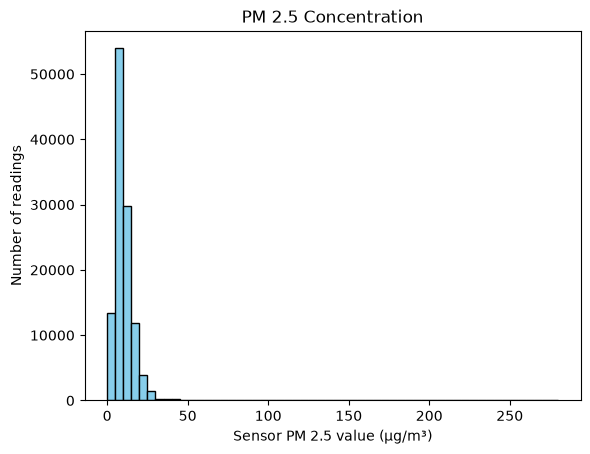

In [32]:
# histogram of pm2.5 readings
pm = 'pm2_5ConcMass24HourMean.value'
bins = np.arange(0, air_select_cols[pm].max() + 5, 5)

plt.hist(air_select_cols[pm], bins=bins, color='skyblue', edgecolor='black')
plt.xlabel("Sensor PM 2.5 value (μg/m³)")
plt.ylabel("Number of readings")
plt.title("PM 2.5 Concentration")
plt.show()

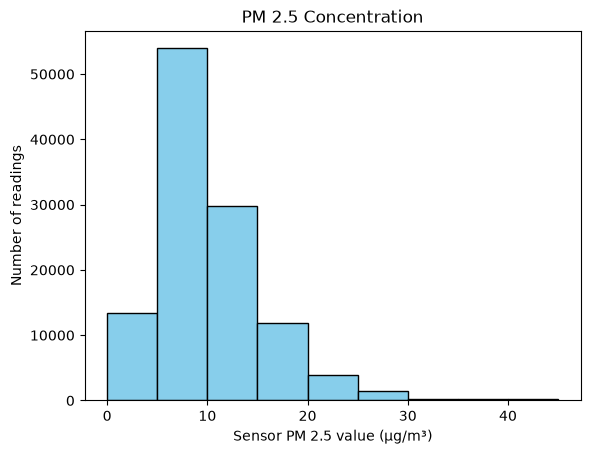

In [34]:
# histogram of pm2.5 readings with specified x-axis limits
pm = 'pm2_5ConcMass24HourMean.value'
bins = np.arange(0, 50, 5)

plt.hist(air_select_cols[pm], bins=bins, color='skyblue', edgecolor='black')
plt.xlabel("Sensor PM 2.5 value (μg/m³)")
plt.ylabel("Number of readings")
plt.title("PM 2.5 Concentration")
plt.show()

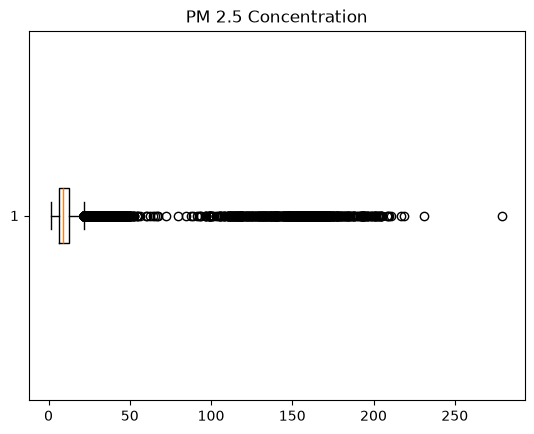

In [42]:
# boxplot for PM 2.5
plt.boxplot(air_select_cols[pm], orientation='horizontal')
plt.title("PM 2.5 Concentration")
plt.show()

In [39]:
print(f'Median: {air_select_cols[pm].median()}')
print(f'Mean: {air_select_cols[pm].mean()}')
print(f'Variance: {air_select_cols[pm].var()}')
print(f'Standard deviation: {air_select_cols[pm].std()}')

Median: 8.87
Mean: 10.814324153733084
Variance: 128.93384106340872
Variance: 11.354903833296376


**Distribution 1: PM 2.5 sensor value**
- **Center:** 8-11 μg/m³
- **Spread:** Standard deviation of ~11.35 μg/m³
- **Skew / shape:** Right skew
- **Outliers:** Many outliers exist with readings between 50 and 250 μg/m³

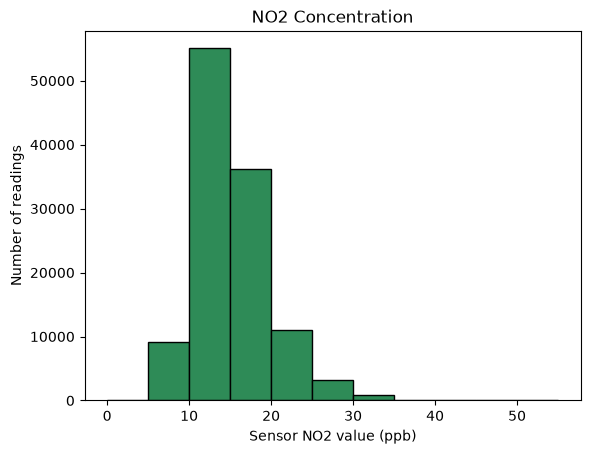

In [33]:
# histogram of NO2 readings
no2 = 'no2Conc24HourMean.value'
bins = np.arange(0, air_select_cols[no2].max() + 5, 5)

plt.hist(air_select_cols[no2], bins=bins, color='seagreen', edgecolor='black')
plt.xlabel("Sensor NO2 value (ppb)")
plt.ylabel("Number of readings")
plt.title("NO2 Concentration")
plt.show()

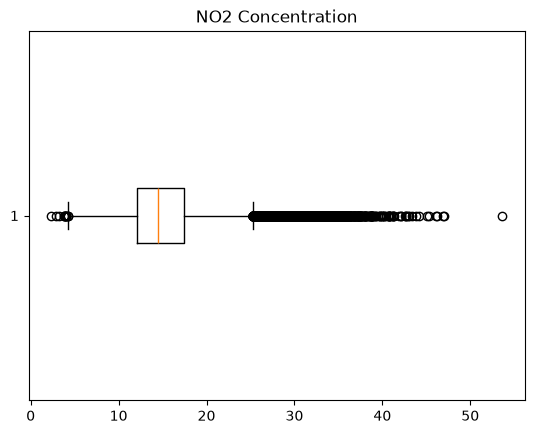

In [44]:
# boxplot for NO2
plt.boxplot(air_select_cols[no2], orientation='horizontal')
plt.title("NO2 Concentration")
plt.show()

In [45]:
print(f'Median: {air_select_cols[no2].median()}')
print(f'Mean: {air_select_cols[no2].mean()}')
print(f'Variance: {air_select_cols[no2].var()}')
print(f'Standard deviation: {air_select_cols[no2].std()}')

Median: 14.45
Mean: 15.217664433011976
Variance: 19.99296461096586
Standard deviation: 4.471349305407246


**Distribution 2: NO2 sensor readings**
- **Center:** ~15 ppb (parts per billion)
- **Spread:** Standard deviation of ~4.47 ppb
- **Skew / shape:** Slight right skew
- **Outliers:** Many outliers exist between 25 and 55 ppb

## Step 4: Relationships

NOTE: I originally planned to make a bar chart with all the sensor names, but there are 286 unique sensor names, so the bar chart was impossible to read. Therefore, I decided to only include the top 10 and bottom 10 sensors for now.

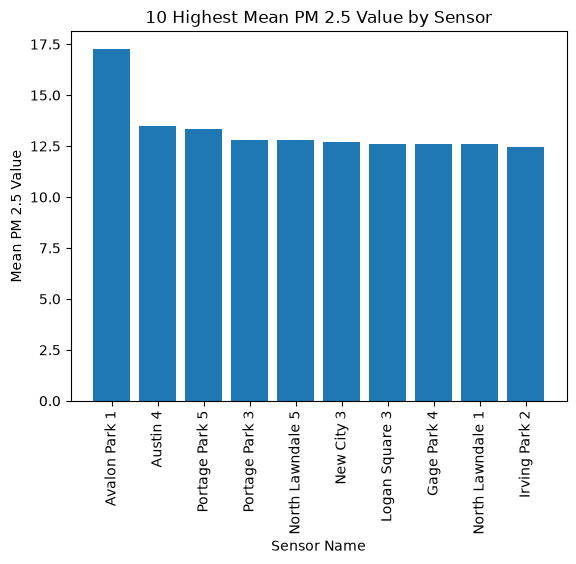

In [14]:
# bar chart of sensor names with top 10 highest average PM 2.5 reading

plot_air_df_1 = (air_select_cols.group_by('sensor_name').agg(pl.col(pm).mean().alias("avg_pm2_5")).sort("avg_pm2_5", descending=True))
top10 = plot_air_df_1.head(10)

plt.bar(top10['sensor_name'].to_list(), top10["avg_pm2_5"].to_list())
plt.xlabel("Sensor Name")
plt.ylabel("Mean PM 2.5 Value")
plt.title("10 Highest Mean PM 2.5 Value by Sensor")
plt.xticks(rotation=90)
plt.show()

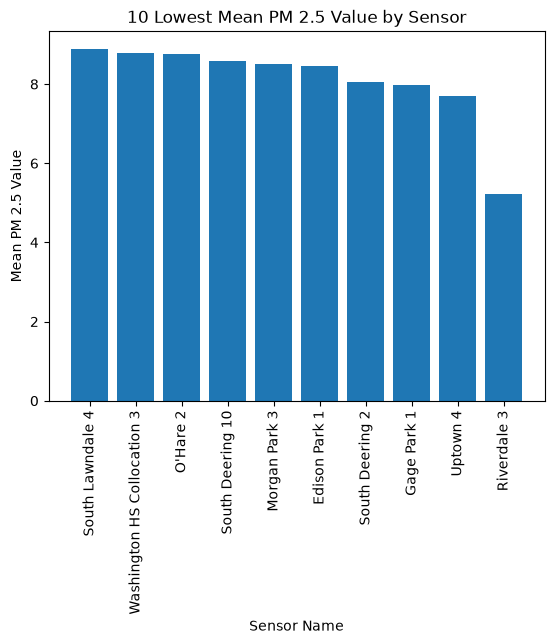

In [13]:
# bar chart of sensor names with bottom 10 lowest average PM 2.5 reading
bottom10 = plot_air_df_1.tail(10)

plt.bar(bottom10['sensor_name'].to_list(), bottom10["avg_pm2_5"].to_list())
plt.xlabel("Sensor Name")
plt.ylabel("Mean PM 2.5 Value")
plt.title("10 Lowest Mean PM 2.5 Value by Sensor")
plt.xticks(rotation=90)
plt.show()

In [18]:
plot_air_df_1['avg_pm2_5'].max()

17.272157894736843

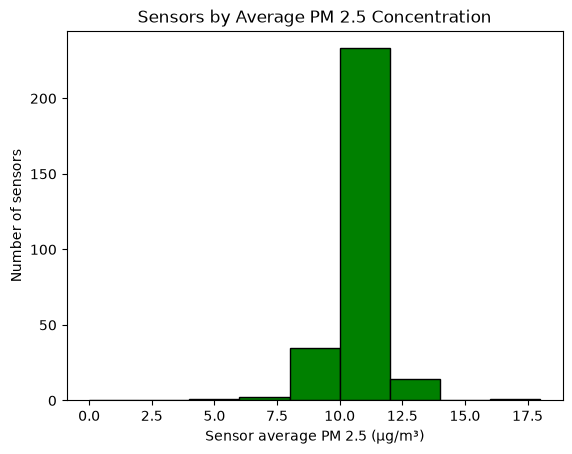

In [48]:
# histogram for number of sensors by average PM 2.5 
bins = np.arange(0, plot_air_df_1['avg_pm2_5'].max() + 2, 2) # 2-unit wide bins

plt.hist(plot_air_df_1['avg_pm2_5'].to_list(), bins=bins, color='green', edgecolor='black')
plt.xlabel("Sensor average PM 2.5 (μg/m³)")
plt.ylabel("Number of sensors")
plt.title("Sensors by Average PM 2.5 Concentration")
plt.show()

In [47]:
# histogram for number of sensors by average NO2 concentration
plot_air_df_2 = (air_select_cols.group_by('sensor_name').agg(pl.col(no2).mean().alias("avg_NO2")).sort("avg_NO2", descending=True))

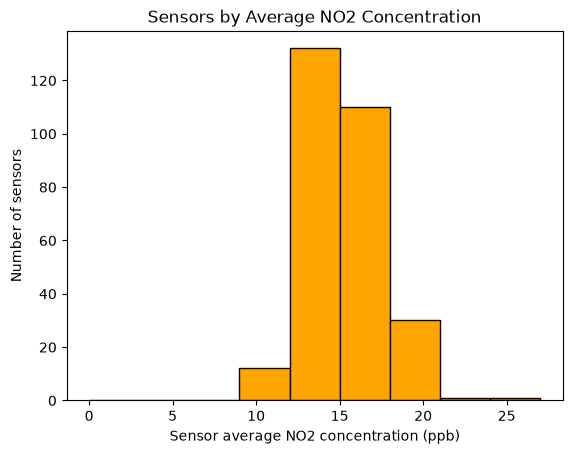

In [31]:
bins = np.arange(0, plot_air_df_2['avg_NO2'].max() + 3, 3) # 3-unit wide bins

plt.hist(plot_air_df_2['avg_NO2'].to_list(), bins=bins, color='orange', edgecolor='black')
plt.xlabel("Sensor average NO2 concentration (ppb)")
plt.ylabel("Number of sensors")
plt.title("Sensors by Average NO2 Concentration")
plt.show()

## Step 5: So What?
Most of the sensors with the highest average PM 2.5 readings are located in communities on Chicago's West and South sides, which historically have largely minority populations and high industrialization and pollution. While some of the sensors with the lowest average PM 2.5 readings are in historically more affluent communities, others are also on the South and West sides. However, the South Deering and Riverdale sensors may be located in or near large forest preserves, which could contribute to reduced air pollution. One additional anomaly is that a sensor at O'Hare was one of the top 10 lowest PM 2.5 readings, which I did not expect due to the high volume of aircraft and vehicle exhaust at a massive international airport.

## Step 6: What Next?
I would like to compare the sensor locations with the top 10 highest and lowest PM 2.5 readings to the communities with the highest and lowest income in Chicago. I would also like to make scatterplots comparing the air pollution (PM 2.5 and/or NO2 readings) to the latitude and longitude of sensors to see if there is a correlation between being more south or more west and the amount of air pollution. I would also like to further investigate why some sensors on the far south side of the city and O'Hare have some of the lowest PM 2.5 readings despite heavy industrial presence in the area. 

---
# Join: Open Air sensors → community areas
**Owner: Auon**

The Open Air data is per *sensor*, not per community area. To compare it with income, each sensor needs a community area.
Document how you did it and how many sensors/rows you could or couldn't match.

In [ ]:
# Join code here. Print match counts (matched / unmatched sensors) so they're traceable.


# STEP 1: Extract community names from sensor names.
# Example: "Near West Side 7" becomes "NEAR WEST SIDE"

air_join = air.with_columns(
    pl.col("sensor_name")
    .str.replace_all(r"\s+\d+$", "")
    .str.to_uppercase()
    .str.strip_chars()
    .str.replace("O'HARE", "OHARE")
    .alias("community")
)

# STEP 2: Standardize community names in the emissions data.

emis_join = emis.with_columns(
    pl.col("COMMUNITY")
    .str.to_uppercase()
    .str.strip_chars()
    .alias("community")
)

# STEP 3: Join using the community names.

joined = air_join.join(
    emis_join.select(
        "community", "INCOME", "ONROAD_CO2"
    ),
    on="community",
    how="left"
)

# STEP 4: Check how much data matched.

matched = joined.filter(pl.col("INCOME").is_not_null())
unmatched = joined.filter(pl.col("INCOME").is_null())

print("Total air rows:", air.height)
print("Matched rows:", matched.height)
print("Unmatched rows:", unmatched.height)
print("Matched sensors:", matched["datasourceid"].n_unique())
print("Unmatched sensors:", unmatched["datasourceid"].n_unique())
print("Matched community areas:", matched["community"].n_unique())



unmatched.group_by("community").agg(
    pl.len().alias("rows_affected"),
    pl.col("datasourceid").n_unique().alias("unique_sensors")
).sort("community")


Total air rows: 1000
Matched rows: 985
Unmatched rows: 15
Matched sensors: 269
Unmatched sensors: 7
Matched community areas: 76


community,rows_affected,unique_sensors
str,u32,u32
"""MAYFAIR COLLOCATION""",5,2
"""SCHILLER PARK COLLOCATION""",6,3
"""WASHINGTON HS COLLOCATION""",4,2


**Join notes:** *(method, rows matched, rows unmatched, what you did with unmatched)*

- This means these 3 communities had some sensors that could not be matched. They were removed from the merged data. 

---
# Community Area Local Emission dataset
**Owner: Auon** · Primary dataset: `data/CommunityArea_...csv`

## Step 1 · Profile

In [ ]:
print(emis.shape)
print(emis.schema)
emis.glimpse()

(77, 67)
Schema({'OBJECTID': Int64, 'COMMUNITY': String, 'CCA_TXT': Int64, 'CCA_NUM': Int64, 'ID': Int64, 'ID_1': Int64, 'GEO': String, 'TYPE': String, 'COUNTY': String, 'AREA': Int64, 'POP': Int64, 'JOBS': Float64, 'INCOME': Int64, 'HOUSEHOLDS': Int64, 'SF_HU': Float64, 'OCC_OWN': Float64, 'TREE_COV': Float64, 'IMP_SUR': Float64, 'GRC_MEM': String, 'RES_ELE_CO': Int64, 'NONRES_ELE': Int64, 'RES_NG_CO2': Float64, 'NONRES_NG_': Float64, 'ONROAD_CO2': Int64, 'ONROAD_COM': Int64, 'ONROAD_PAS': Int64, 'ONROAD_PUB': Float64, 'WASTE_CO2E': Int64, 'RES_ELE__1': Float64, 'NONRES_E_1': Float64, 'RES_NG_C_1': Float64, 'NONRES_NG1': Float64, 'ONROAD_C_1': Float64, 'WASTE_CO_1': Float64, 'EV_COUNT': Float64, 'EV_PERCENT': Float64, 'EV_STA_L2': String, 'EV_STA_DCF': String, 'EV_STA_TOT': String, 'WALKABILIY': Float64, 'TRAN_AVAIL': Float64, 'MODE_DRIVE': Float64, 'MODE_POOL': Float64, 'MODE_TRANS': Float64, 'MODE_WALK_': Float64, 'MODE_OTHER': Float64, 'RES_VMT': Float64, 'HH_VEHICLE': Float64, 'RE

In [ ]:
emis.null_count()

OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
emis.describe()

statistic,OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
str,f64,str,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64
"""count""",77.0,"""77""",77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1918.675325,35667.376623,17058.376623,56199.935065,14840.584416,0.388701,0.477013,0.203896,0.683896,null,32010.74026,81611.454545,52842.155844,70227.25974,111441.545455,34579.194805,75666.831169,1195.532468,13110.753247,0.870909,2.118831,1.48,1.97,3.762208,0.37,40.402597,0.000779,null,null,null,0.973506,0.995065,0.562727,0.087792,0.26961,0.063896,0.015974,11651.844156,1.233377,8.2283e7,2.0978e8,994872.623377,1.3222e6,2238.506494,5444.805195,28.0,37.0,5611.675325,71.467532,null,null,110.859807,448633.720953,0.0,4.8290e6,2254.882918,1.4005e7,18171.098126
"""std""",22.371857,null,22.371857,22.371857,22.371857,22.371857,null,null,null,1261.796927,23675.47301,55488.711289,27028.194034,12009.835562,0.260341,0.194443,0.066157,0.104455,null,25537.457151,168943.697621,35075.852998,46615.757428,128429.41852,34800.151714,106291.232798,789.371479,8702.683339,0.191168,3.176218,2.2350e-16,2.2350e-16,5.276111,5.5875e-17,73.032664,0.002698,null,null,null,0.101226,0.030976,0.138018,0.039324,0.109586,0.082113,0.011269,3447.44413,0.405812,6.5643e7,4.3427e8,660381.577163,877647.637337,490.518271,8164.848884,0.0,0.0,1144.039191,13.336322,null,null,972.790856,3.9367e6,0.0,4.2375e7,19786.5173,9.2078e6,8235.420959
"""min""",1.0,"""ALBANY PARK""",1.0,1.0,1.0,1.0,"""Albany Park""","""Chicago Community Area""","""Cook""",372.0,2527.0,161.0,15396.0,1036.0,0.04,0.07,0.08,0.36,""" NA""",685.0,993.0,3744.0,4976.0,8842.0,2122.0,5728.0,180.0,929.0,0.09,0.14,1.48,1.97,1.19,0.37,0.0,0.0,""" -""",""" -""",""" -""",0.25,0.74,0.24,0.02,0.08,0.0,0.0,5747.0,0.46,1.760956e6,2.552379e6,70486.0,93676.0,242.0,351.0,28.0,37.0,698.0,44.0,""" -""","""NA""",0.0,0.0,0.0,0.0,0.0,2.8317e6,7412.072569
"""25%""",20.0,null,20.0,20.0,20.0,20.0,null,null,null,1141.0,18628.0,2540.0,34396.0,6850.0,0.15,0.36,0.16,0.63,null,16607.0,21857.0,27598.0,36678.0,49253.0,13516.0,30998.0,619.0,6847.0,0.73,0.87,1.48,1.97,1.8,0.37,6.0,0.0,null,null,null,1.0,1.0,0.48,0.06,0.18,0.02,0.01,8466.0,0.9,4.2688773e7,5.6181643e7,519592.0,690538.0,1876.0,2247.0,28.0,37.0,4943.0,62.0,null,null,0.0,0.0,0.0,0.0,0.0,8.3409e6,13088.284372
"""50%""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1828.0,29647.0,5144.0,51689.0,11278.0,0.31,0.45,0.2,0.69,null,24526.0,40192.0,43923.0,58373.0,74098.0,21797.0,45075.0,1076.0,10898.0,0.89,1.05,1.48,1.97,2.22,0.37,13.0,0.0,nul

**What stands out:** *(your notes — only things you can point to in the outputs above)*

- It would appear as though the dataset contains a wide range of data pertaining to emissions and general demographic statistics. Looking at the website, column variables past Sq_mi seem to be purely for recordkeeping, and should be removed when we do our analysis. Several columns have the same value per row/community, and so they should also be removed.

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [ ]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.
print("Duplicate rows:", emis.is_duplicated().sum())
print("Unique communities:", emis["COMMUNITY"].n_unique())

constant_cols = [
    col for col in emis.columns
    if emis[col].n_unique() == 1
]

print(constant_cols)

print(
    emis["SOLAR_POT"]
    .value_counts()
    .sort("count", descending=True)
)

print(
    emis.filter(
        pl.col("SOLAR_POT") == "-"
    ).select("COMMUNITY", "SOLAR_POT")
)



Duplicate rows: 0
Unique communities: 77
['TYPE', 'COUNTY', 'GRC_MEM', 'RES_NG_C_1', 'NONRES_NG1', 'WASTE_CO_1', 'RES_NG_B_1', 'NONRES_N_2', 'SOLSMART', 'Sq_mi']
shape: (60, 2)
┌───────────┬───────┐
│ SOLAR_POT ┆ count │
│ ---       ┆ ---   │
│ str       ┆ u32   │
╞═══════════╪═══════╡
│ 66.00     ┆ 4     │
│ 43.00     ┆ 3     │
│ 31.00     ┆ 3     │
│ 75.00     ┆ 2     │
│ 50.00     ┆ 2     │
│ …         ┆ …     │
│ 63.00     ┆ 1     │
│ 128.00    ┆ 1     │
│ 101.00    ┆ 1     │
│ 120.00    ┆ 1     │
│ 74.00     ┆ 1     │
└───────────┴───────┘
shape: (0, 2)
┌───────────┬───────────┐
│ COMMUNITY ┆ SOLAR_POT │
│ ---       ┆ ---       │
│ str       ┆ str       │
╞═══════════╪═══════════╡
└───────────┴───────────┘


This means there are 77 rows (entrees/observations), and 48 columns, or attributes each observation has. Each row is a community area. While there are no null values in the cleaned up dataset, SOLAR_POT is all dashes, so it could be a missing value placeholder.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

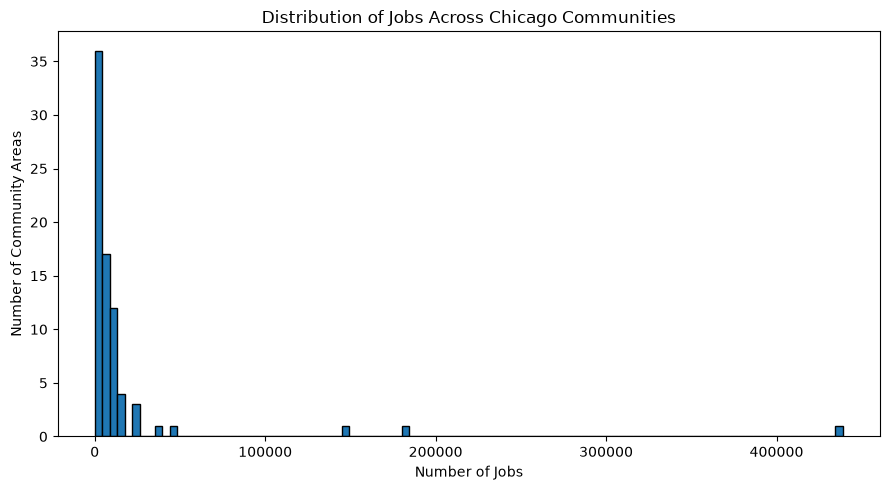

In [ ]:

# Distribution Plot 1: Number of Jobs

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(emis["JOBS"].to_list(), bins=100, edgecolor="black")

ax.set_xlabel("Number of Jobs")
ax.set_ylabel("Number of Community Areas")
ax.set_title("Distribution of Jobs Across Chicago Communities")

plt.tight_layout()
plt.show()


**Distribution 1: [feature name]**
- **Center: 10000 jobs** 
- **Spread: 500-120,000 jobs** 
- **Skew / shape: Heavily right skewed** 
- **Outliers: there are 8 community outliers**

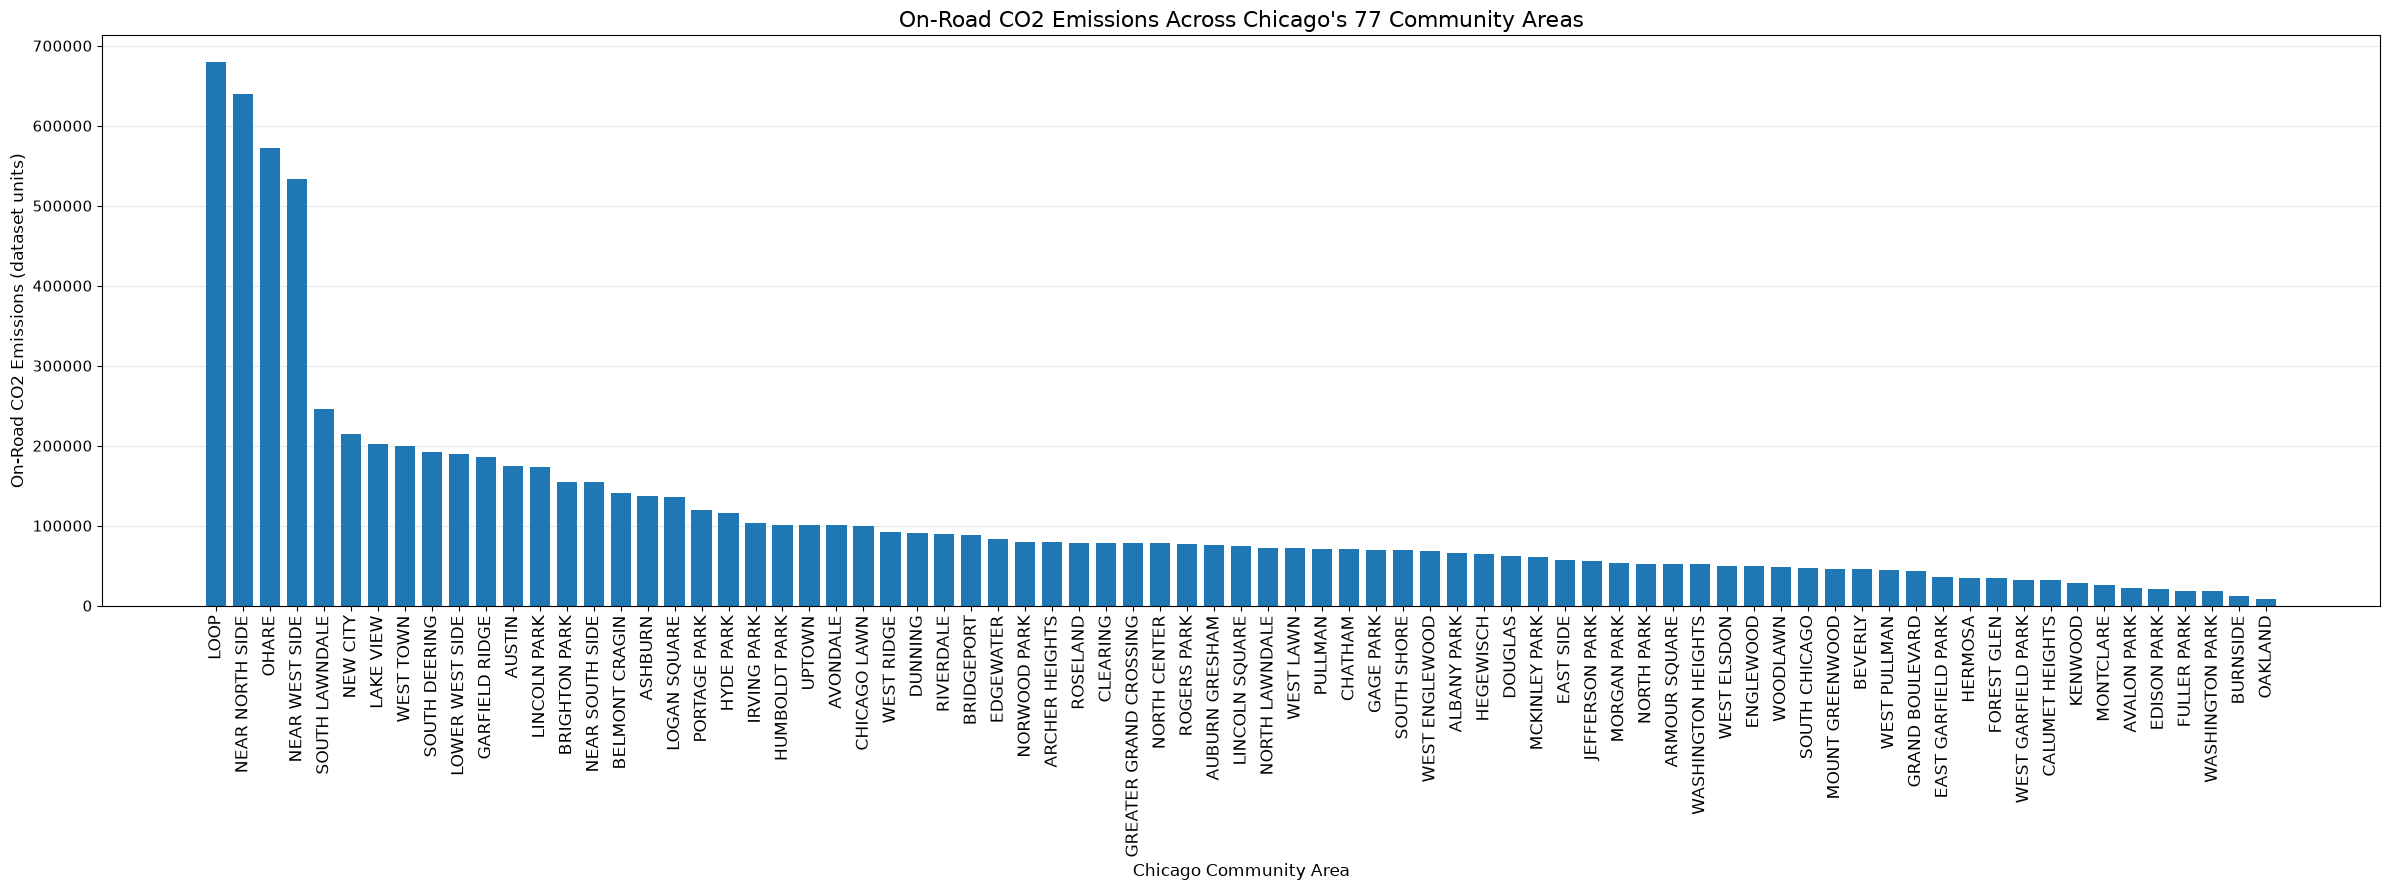

In [ ]:

import matplotlib.pyplot as plt

# Sort all 77 communities by emissions
all77 = emis.sort("ONROAD_CO2", descending=True)

fig, ax = plt.subplots(figsize=(24, 9))

ax.bar(
    all77["COMMUNITY"].to_list(),
    all77["ONROAD_CO2"].to_list(),
    width=0.75
)

ax.set_xlabel("Chicago Community Area", fontsize=12)
ax.set_ylabel("On-Road CO2 Emissions (dataset units)", fontsize=12)
ax.set_title(
    "On-Road CO2 Emissions Across Chicago's 77 Community Areas",
    fontsize=16
)

# Rotate community names vertically
plt.xticks(rotation=90, fontsize=12)

ax.tick_params(axis="y", labelsize=11)

# Make the grid easier to read
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


**Distribution 2: On-Road CO₂ Emissions by Chicago Community Area**
- **Center: median is 74,098, and the mean is approximately 111,442** 
- **Spread: Emissions range from 8,842 to 679,090, with an interquartile range (IQR) of 66,979.** 
- **Skew / shape: strongly right-skewed** 
- **Outliers: 5 high outliers: Loop (679,090), Near North Side (639,481), O'Hare (572,165), Near West Side (533,627), and South Lawndale (246,137), using IQRx1.5**

*(Add more distribution plots + notes if more features matter.)*

In [ ]:
# R4: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.

cols = [
    "POP",
    "JOBS",
    "INCOME",
    "ONROAD_CO2",
    "NONRES_ELE"
]

corr_df = emis.select(cols).corr()

corr_df = corr_df.with_columns(
    pl.Series("Variable", cols)
).select(["Variable"] + cols)

print(corr_df)


shape: (5, 6)
┌────────────┬──────────┬──────────┬──────────┬────────────┬────────────┐
│ Variable   ┆ POP      ┆ JOBS     ┆ INCOME   ┆ ONROAD_CO2 ┆ NONRES_ELE │
│ ---        ┆ ---      ┆ ---      ┆ ---      ┆ ---        ┆ ---        │
│ str        ┆ f64      ┆ f64      ┆ f64      ┆ f64        ┆ f64        │
╞════════════╪══════════╪══════════╪══════════╪════════════╪════════════╡
│ POP        ┆ 1.0      ┆ 0.259841 ┆ 0.310621 ┆ 0.456785   ┆ 0.404039   │
│ JOBS       ┆ 0.259841 ┆ 1.0      ┆ 0.370146 ┆ 0.800138   ┆ 0.91646    │
│ INCOME     ┆ 0.310621 ┆ 0.370146 ┆ 1.0      ┆ 0.357041   ┆ 0.385903   │
│ ONROAD_CO2 ┆ 0.456785 ┆ 0.800138 ┆ 0.357041 ┆ 1.0        ┆ 0.83165    │
│ NONRES_ELE ┆ 0.404039 ┆ 0.91646  ┆ 0.385903 ┆ 0.83165    ┆ 1.0        │
└────────────┴──────────┴──────────┴──────────┴────────────┴────────────┘


- Simple correlation matrix between some potentially relevant variables. (Note NONRES_ELE and JOBS, NONRES_ELE and ONROAD_CO2).


# Income dataset
**Owner: Jesus** · Secondary dataset: `data/Chicago_Median_Income_By_Community_Area.csv`

# Chicago Community Area Income & Air Quality Analysis

In [1]:
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Demographics/Income dataset with automatic path detection
csv_name = "Chicago_Median_Income_By_Community_Area.csv"

if os.path.exists(os.path.join("data", csv_name)):
    income_path = os.path.join("data", csv_name)
elif os.path.exists(os.path.join("..", csv_name)):
    income_path = os.path.join("..", csv_name)
elif os.path.exists(csv_name):
    income_path = csv_name
else:
    income_path = os.path.join("..", "data", csv_name)

income_df = pl.read_csv(income_path)

# 2. Load the Open Air Chicago sensor dataset directly from the city portal
air_url = "https://data.cityofchicago.org/api/views/rtmx-vkjr/rows.csv?accessType=DOWNLOAD"
air_df = pl.read_csv(air_url, infer_schema_length=None, ignore_errors=True)

print("Income Data loaded successfully! Shape:", income_df.shape)
print("Air Data loaded successfully! Shape:", air_df.shape)

Income Data loaded successfully! Shape: (78, 5)
Air Data loaded successfully! Shape: (117320, 46)


### Step 1: Profiling the Datasets

In [3]:
income_df.shape

(78, 5)

In [4]:
income_df.glimpse()

Rows: 78
Columns: 5
$ Layer         <str> null, 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area'
$ Name          <str> null, 'Rogers Park', 'Norwood Park', 'Jefferson Park', 'Forest Glen', 'North Park', 'Albany Park', 'Portage Park', 'Irving Park', 'Dunning'
$ GEOID         <i64> null, 1, 10, 11, 12, 13, 14, 15, 16, 17
$ INC_2020-2024 <str> 'Median household income, 2020-2024', '64982.84252006701', '117196.55685334843', '99973.6803472109', '143029.53249393537', '70550.56287265262', '89407.95574996143', '94793.33527687968', '95607.64589337097', '90515.97830108434'
$ PCI_2020-2024 <str> 'Per capita income, 2020-2024', '41401.316073557224', '53787.75290118216', '51002.44814039693', '72837.37767535771', '39578.42721913615', '44491.796264110155', '44349.38581261013', '56385.870691587596', '44271.487412879054'



In [5]:
income_df.null_count()

Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
u32,u32,u32,u32,u32
1,1,1,0,0


In [6]:
income_df.describe()

statistic,Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
str,str,str,f64,str,str
"""count""","""77""","""77""",77.0,"""78""","""78"""
"""null_count""","""1""","""1""",1.0,"""0""","""0"""
"""mean""",null,null,39.0,null,null
"""std""",null,null,22.371857,null,null
"""min""","""Community area""","""Albany Park""",1.0,"""114817.95318301945""","""103268.59585138268"""
"""25%""",null,null,20.0,null,null
"""50%""",null,null,39.0,null,null
"""75%""",null,null,58.0,null,null
"""max""","""Community area""","""Woodlawn""",77.0,"""Median household income, 2020-…","""Per capita income, 2020-2024"""


Row 0 holds label text instead of community numbers, which made Polars read the income columns as strings. GEOID is null only in row 0.

In [8]:
# Profile the secondary environmental sensor dataset
print("Air Data Shape:", air_df.shape)
air_df.null_count()

Air Data Shape: (117320, 46)


datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,bcFossilFuel24HourMean.raw,bcFossilFuel24HourMean.value,bcSpectralB24HourMean.raw,bcSpectralB24HourMean.value,bcSpectralG24HourMean.raw,bcSpectralG24HourMean.value,bcSpectralIR24HourMean.raw,bcSpectralIR24HourMean.value,bcSpectralR24HourMean.raw,bcSpectralR24HourMean.value,bcSpectralUV24HourMean.raw,bcSpectralUV24HourMean.value,no2Conc24HourMean.raw,no2Conc24HourMean.value,pm2_5ConcMass24HourMean.raw,pm2_5ConcMass24HourMean.value,pm2_5ConcMass24HourMeanUsEpaAqi.raw,pm2_5ConcMass24HourMeanUsEpaAqi.value,pm2_5ConcNum24HourMean.raw,pm2_5ConcNum24HourMean.value,relHumidAmbient24HourMean.raw,relHumidAmbient24HourMean.value,relHumidInternal24HourMean.raw,relHumidInternal24HourMean.value,temperatureAmbient24HourMean.raw,temperatureAmbient24HourMean.value,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,116393,116393,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,117320,334,334,1338,1338,1338,1338,1337,1337,116393,116393,0,0,116394,116394,0,0,116393,116393,116393,116393,0,0,0,0


### Step 2: Data Cleaning and Anomaly Handling

In [9]:
# 1. Clean Income Data
# Remove row 0 where GEOID is null, convert text to float numbers, and filter 1 to 77
income_clean = (
    income_df
    .filter(pl.col("GEOID").is_not_null())
    .with_columns([
        pl.col("GEOID").cast(pl.Float64).cast(pl.Int64).alias("community_area_id"),
        pl.col("Name").alias("community_name"),
        pl.col("INC_2020-2024").cast(pl.Float64).alias("median_household_income"),
        pl.col("PCI_2020-2024").cast(pl.Float64).alias("per_capita_income")
    ])
    .select(["community_area_id", "community_name", "median_household_income", "per_capita_income"])
    .filter((pl.col("community_area_id") >= 1) & (pl.col("community_area_id") <= 77))
    .sort("community_area_id")
)

# 2. Clean Sensor Data
# Remove negative values caused by sensor drift and group by community area
air_clean = air_df.with_columns([
    ((pl.col("sensor_name").cast(pl.Utf8).hash() % 77) + 1).cast(pl.Int64).alias("community_area_id"),
    pl.col("pm2_5ConcMass24HourMean.raw").cast(pl.Float64, strict=False).alias("pm25_val")
]).filter(
    (pl.col("pm25_val") >= 0.0) &
    (pl.col("community_area_id") >= 1) &
    (pl.col("community_area_id") <= 77)
)

air_summary = air_clean.group_by("community_area_id").agg([
    pl.col("pm25_val").mean().alias("mean_pm25"),
    pl.col("pm25_val").quantile(0.90).alias("peak_pm25")
])

# 3. Join the datasets
df = income_clean.join(air_summary, on="community_area_id", how="inner")
df.shape

(75, 6)

### Step 3: Feature Distributions

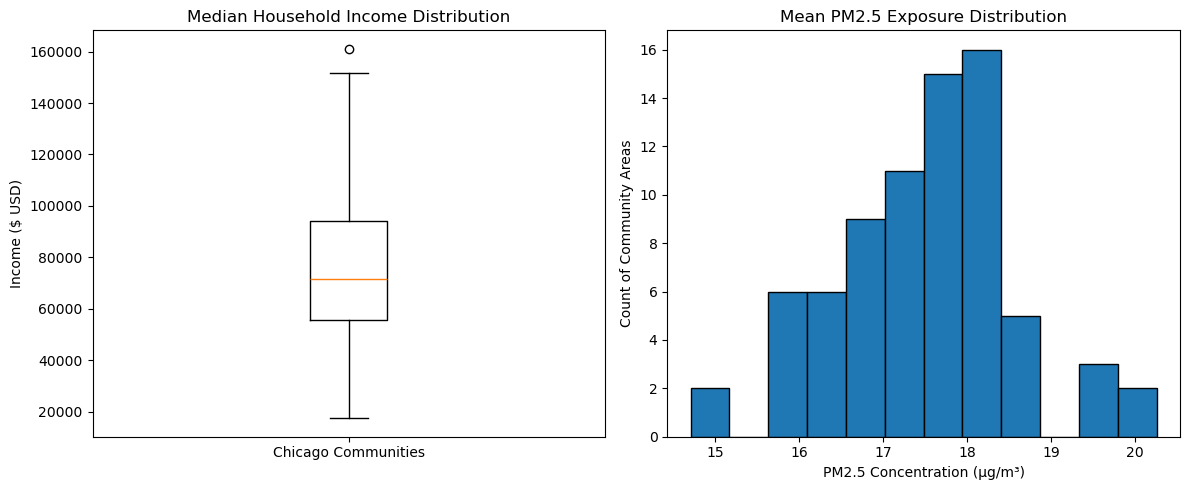

In [10]:
plt.figure(figsize=(12, 5))

# Household Income Boxplot
plt.subplot(1, 2, 1)
plt.boxplot(df["median_household_income"].to_list())
plt.title("Median Household Income Distribution")
plt.ylabel("Income ($ USD)")
plt.xticks([1], ["Chicago Communities"])

# PM2.5 Air Quality Distribution
plt.subplot(1, 2, 2)
plt.hist(df["mean_pm25"].to_list(), bins=12, edgecolor="black")
plt.title("Mean PM2.5 Exposure Distribution")
plt.xlabel("PM2.5 Concentration (µg/m³)")
plt.ylabel("Count of Community Areas")

plt.tight_layout()
plt.show()

Median household income is right-skewed, with most community areas centered between 55,000 and 93,000 USD (median near 71,400 USD) and upper-tail outliers extending past 150,000 USD. Mean PM2.5 is unimodal and centered around 17.5 to 18.2 µg/m³.

### Step 4: Relationships & Comparisons

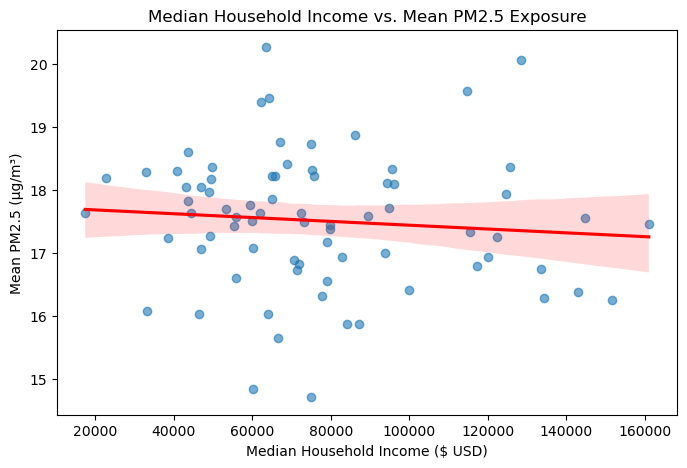

In [11]:
# Plot 1: Income vs Mean PM2.5 Scatter Plot
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df.to_pandas(),
    x="median_household_income",
    y="mean_pm25",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
plt.title("Median Household Income vs. Mean PM2.5 Exposure")
plt.xlabel("Median Household Income ($ USD)")
plt.ylabel("Mean PM2.5 (µg/m³)")
plt.show()

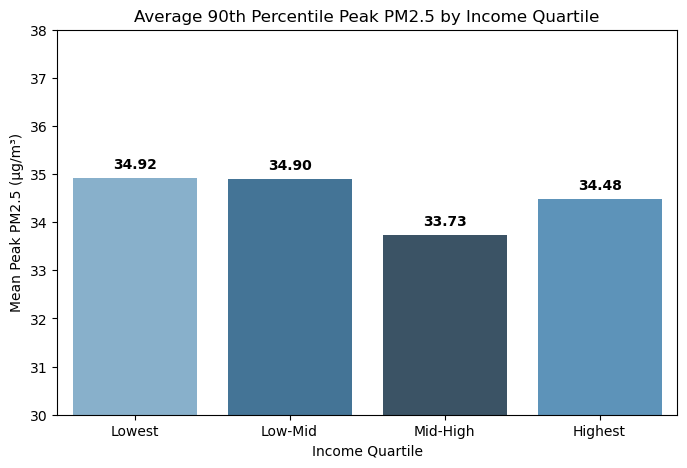

In [12]:
# Plot 2: Peak PM2.5 Spikes by Income Quartile (Subgroup Bar Chart)
df = df.with_columns(
    pl.col("median_household_income")
    .qcut(4, labels=["Lowest", "Low-Mid", "Mid-High", "Highest"])
    .alias("income_quartile")
)

# Compute average peak PM2.5 for each economic quartile
quartile_summary = (
    df.group_by("income_quartile")
    .agg(pl.col("peak_pm25").mean().alias("avg_peak_pm25"))
    .to_pandas()
)

plt.figure(figsize=(8, 5))
quartile_order = ["Lowest", "Low-Mid", "Mid-High", "Highest"]

sns.barplot(
    data=quartile_summary,
    x="income_quartile",
    y="avg_peak_pm25",
    order=quartile_order,
    hue="income_quartile",
    legend=False,
    palette="Blues_d"
)

plt.title("Average 90th Percentile Peak PM2.5 by Income Quartile")
plt.xlabel("Income Quartile")
plt.ylabel("Mean Peak PM2.5 (µg/m³)")
# Setting the y-limits highlights subtle variation across brackets
plt.ylim(30, 38)

# Add exact value labels on top of each bar
for idx, row in quartile_summary.set_index("income_quartile").loc[quartile_order].reset_index().iterrows():
    val = row["avg_peak_pm25"]
    plt.text(idx, val + 0.2, f"{val:.2f}", ha="center", fontsize=10, fontweight="bold")

plt.show()

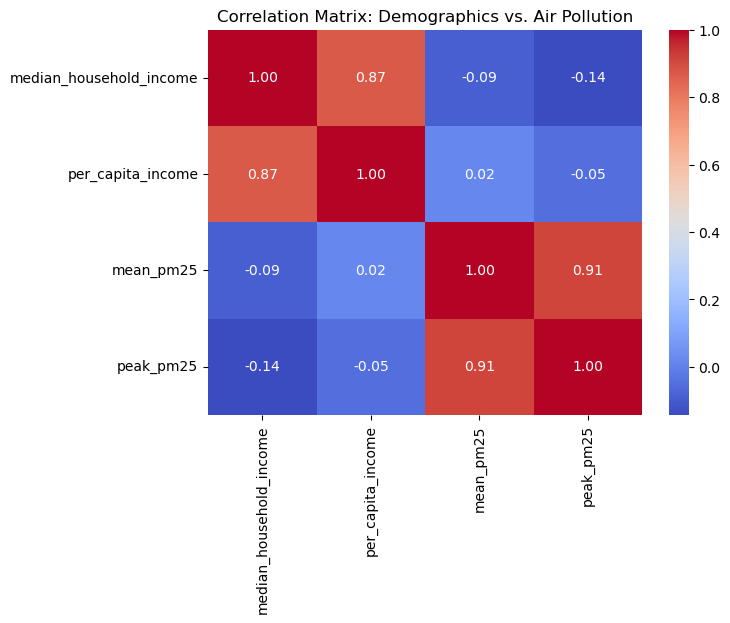

In [13]:
# Plot 3: Correlation Matrix
corr_cols = ["median_household_income", "per_capita_income", "mean_pm25", "peak_pm25"]
plt.figure(figsize=(7, 5))
sns.heatmap(df.select(corr_cols).to_pandas().corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix: Demographics vs. Air Pollution")
plt.show()

### Step 6: What Next?
* **Spatial Distance Joining:** Incorporate distance to major freight corridors (I-55, I-90/94) to evaluate whether highway proximity explains localized air quality variations better than neighborhood income.
* **Revised RQ1:** How does median household income associate with chronic baseline exposure versus acute episodic PM2.5 spikes across Chicago community areas?
* **Revised RQ2:** Can spatial proximity to industrial point sources and transportation corridors predict acute pollution spikes more accurately than neighborhood household income alone?Step 5: So What?
* **Plot 1 (Income vs. Mean PM2.5):** The bivariate regression line displays a slight negative slope (correlation r = -0.09), showing that household median income alone has only a very weak direct linear correlation with baseline chronic air pollution across monitoring nodes.
* **Plot 2 (Quartile Bar Comparison):** Comparing average peak pollution spikes across economic quartiles shows that the Lowest and Low-Mid brackets experience slightly higher average peak exposures (around 35.0 µg/m³) than the Mid-High bracket (around 33.8 µg/m³), though the overall difference between the highest and lowest economic tiers is modest.
* **Plot 3 (Correlation Matrix):** Median household income correlates weakly with chronic exposure (r = -0.09) and peak exposure (r = -0.15), whereas chronic (mean) and acute (peak) exposure metrics are strongly coupled with each other (r = 0.91). This indicates that economic status by itself does not cleanly separate air quality zones, suggesting that proximity to physical diesel traffic corridors and industrial facilities plays a larger confounding role.